# Week 1: Returns and Risk
Pull ten years of daily data for both assets and compute daily returns from the **Adjusted Close** price.

In [2]:
import pandas as pd

TICKERS = ["TLT", "SHY"]

tlt = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
shy = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)

tlt.tail()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,85.062859,88.029999,88.080002,87.650002,87.760002,25942000
2025-12-26,84.782631,87.739998,88.169998,87.599998,88.099998,26522700
2025-12-29,85.101509,88.070000,88.070000,87.790001,87.949997,29399800
2025-12-30,84.898598,87.860001,88.040001,87.669998,87.739998,25106800
2025-12-31,84.222176,87.160004,87.910004,87.129997,87.680000,36500000


In [3]:
prices = pd.DataFrame({
    "TLT": tlt["Adj Close"],
    "SHY": shy["Adj Close"],
})

returns = prices.pct_change().dropna()
returns.head()

,TLT,SHY
Date,,
2016-01-05,-0.004035,-0.000593
2016-01-06,0.013476,0.000593
2016-01-07,0.001794,0.000354
2016-01-08,0.004479,0.000710
2016-01-11,-0.010944,0.000355


## Visual
A single chart showing **cumulative log-scale returns** for both assets on the same axes.

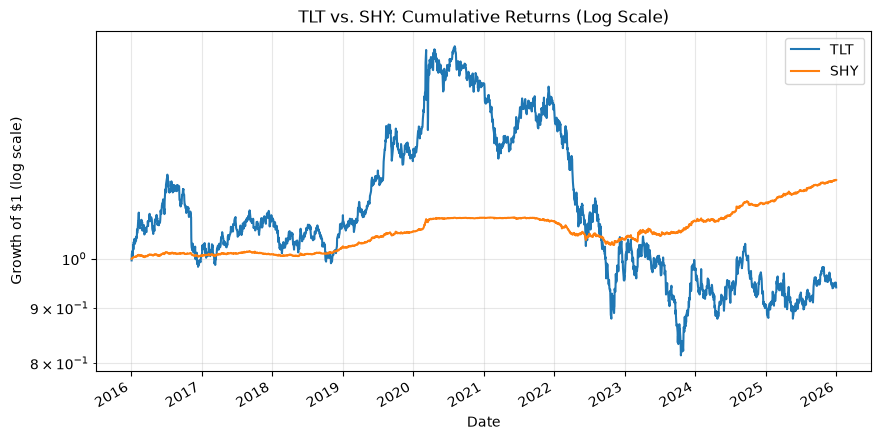

In [7]:
import matplotlib.pyplot as plt

# Growth of $1 invested in each asset
cumulative = (1 + returns).cumprod()

ax = cumulative.plot(figsize=(10, 5), logy=True)
ax.set_title("TLT vs. SHY: Cumulative Returns (Log Scale)")
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_xlabel("Date")
ax.grid(True, which="both", alpha=0.3)
plt.show()

## Table
Side-by-side comparison of **annualized return, annualized volatility, and maximum drawdown**.

In [8]:
import numpy as np

TRADING_DAYS = 252  

# Annualized return (compound growth per year)
n_years = len(returns) / TRADING_DAYS
ann_return = (1 + returns).prod() ** (1 / n_years) - 1

# Annualized volatility
ann_vol = returns.std() * np.sqrt(TRADING_DAYS)

# Maximum drawdown (worst peak-to-trough drop)
cumulative = (1 + returns).cumprod()
running_peak = cumulative.cummax()
drawdown = cumulative / running_peak - 1
max_dd = drawdown.min()

# In one table
summary = pd.DataFrame({
    "Annualized Return": ann_return,
    "Annualized Volatility": ann_vol,
    "Max Drawdown": max_dd,
})

summary.style.format("{:.2%}")

,Annualized Return,Annualized Volatility,Max Drawdown
TLT,-0.62%,14.99%,-48.35%
SHY,1.70%,1.56%,-5.71%


## Context
Find the **five best and five worst days** for each asset, then look up the news to see what caused them.

In [9]:
for ticker in TICKERS:
    print(f"===== {ticker} =====")
    print("5 best days:")
    print(returns[ticker].nlargest(5).map("{:.2%}".format))
    print("\n5 worst days:")
    print(returns[ticker].nsmallest(5).map("{:.2%}".format))
    print("\n")

===== TLT =====
5 best days:
Date
2020-03-20    7.52%
2020-03-16    6.48%
2020-03-06    5.20%
2020-03-23    4.12%
2022-11-10    3.85%
Name: TLT, dtype: str

5 worst days:
Date
2020-03-17    -6.67%
2020-03-18    -5.64%
2020-03-10    -5.13%
2016-11-09    -4.24%
2020-03-11    -3.68%
Name: TLT, dtype: str


===== SHY =====
5 best days:
Date
2023-03-13    1.00%
2023-03-15    0.59%
2024-08-02    0.56%
2020-03-09    0.55%
2023-03-10    0.54%
Name: SHY, dtype: str

5 worst days:
Date
2022-06-13    -0.51%
2022-02-10    -0.51%
2020-03-10    -0.44%
2023-03-27    -0.42%
2022-06-10    -0.42%
Name: SHY, dtype: str




| Asset |      Date     | Return  | What happened | 
| [TLT] | [2020-03-20 ] | [7.52%] | [FILL IN] |
| [TLT] | [2020-03-16]  | [6.48%] | [FILL IN] |
| [TLT] | [2020-03-06]  | [5.20%] | [FILL IN] |
| [TLT] | [2020-03-23]  | [4.12%] | [FILL IN] |
| [TLT] | [2022-11-10]  | [3.85%] | [FILL IN] |
| [TLT] | [2020-03-17] | [-6.67%] | [FILL IN] |
| [TLT] | [2020-03-18] | [-5.64%] | [FILL IN] |
| [TLT] | [2020-03-10] | [-5.13%] | [FILL IN] |
| [TLT] | [2016-11-09] | [-4.24%] | [FILL IN] |
| [TLT] | [2020-03-11] | [-3.68%] | [FILL IN] |


| Asset |     Date     |  Return  | What happened |
| [SHY] | [2023-03-13] | [1.00%]  | [FILL IN] |
| [SHY] | [2023-03-15] | [0.59%]  | [FILL IN] |
| [SHY] | [2024-08-02] | [0.56%]  | [FILL IN] |
| [SHY] | [2020-03-09] | [0.55%]  | [FILL IN] |
| [SHY] | [2023-03-10] | [0.54%]  | [FILL IN] |
| [SHY] | [2022-06-13] | [-0.51%] | [FILL IN] |
| [SHY] | [2022-02-10] | [-0.51%] | [FILL IN] |
| [SHY] | [2020-03-10] | [-0.44%] | [FILL IN] |
| [SHY] | [2023-03-27] | [-0.42%] | [FILL IN] |
| [SHY] | [2022-06-10] | [-0.42%] | [FILL IN] |

## The Paragraph
> **Which asset is actually riskier, and does taking on that extra risk result in a higher return?**

[FILL IN: one paragraph]

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 1: returns and risk"
git push
```